# General relativity 4: Black holes

*Learning path: general relativity, part 4 of 9.* [Index](README.md) · Previous: [Einstein's equations](03-einstein-equations.ipynb) · Next: [Orbits](05-orbits.ipynb)

If a star is smaller than its Schwarzschild radius, nothing can stop its collapse, and a **black hole** forms. This
notebook explores the Schwarzschild spacetime close up, and ends with the spinning Kerr black hole. You will learn

* where the event horizon is, and that it is not a real singularity,
* how strong the tides are (spaghettification), and why big black holes are gentler,
* how long it takes to fall in, for you and for someone watching,
* the shape of space around a black hole (Flamm's paraboloid), and the ergosphere of a spinning one.

## 1. The Schwarzschild metric

In [1]:
S = metric.generate(schwarzschild)

$$ds^2 = - \frac{r - r_{s}}{r}\, dt^2 + \frac{r}{r - r_{s}}\, dr^2 + r^{2}\, d\theta^2 + r^{2} \sin^{2}\left(\theta\right)\, d\phi^2$$

$r_s = 2GM/c^2$. For the Sun it is about 3 km, for the Earth about 9 mm:

In [2]:
G = 6.674e-11;
c = 299792458;
Msun = 1.989e30;
eval(2*G*Msun/c^2)
eval(2*G*5.972e24/c^2)

2953.9937713977156
0.00886940714066725

## 2. The horizon and the singularity

At $r = r_s$, $g_{tt} = 0$ and $g_{rr}$ blows up, and at $r = 0$ both misbehave. Are these real? Components depend on
coordinates, so we look at an invariant, the Kretschmann scalar:

In [3]:
clear
S = metric.generate(schwarzschild);
K = kretschmann(S)

12.0*r_s^2.0/r^6.0

$12 r_s^2/r^6$ is perfectly finite at the horizon $r = r_s$ and infinite at $r = 0$. The horizon is a place where the
coordinates fail, not where spacetime does: someone falling in notices nothing special there. The centre, $r = 0$, is a
true singularity.

## 3. Tides and spaghettification

The tidal stretching in the radial direction is $R^r{}_{ttr} = r_s/r^3$ (part 2): a body of length $\ell$ is pulled apart
with acceleration $c^2 r_s\,\ell/r^3$. At the horizon $r = r_s$ that is $c^2\ell/r_s^2$, so **smaller black holes have
stronger tides**. For a 2 m person at the horizon of a 10 solar mass black hole, and of Sagittarius A*, the 4 million
solar mass black hole at the centre of our galaxy, in units of Earth's gravity $g = 9.81$:

In [4]:
G = 6.674e-11;
c = 299792458;
Msun = 1.989e30;
rs10 = eval(2*G*10*Msun/c^2);
rsSgr = eval(2*G*4.0e6*Msun/c^2);
eval(c^2*2/rs10^2/9.81)
eval(c^2*2/rsSgr^2/9.81)

2.0998256847276255E7
1.3123910529547664E-4

Near the small black hole the stretch is about 20 million $g$: certain spaghettification, well outside the horizon.
At Sagittarius A*, about $10^{-4}\,g$: you would cross the horizon without feeling a thing.

## 4. Falling in

Take an object falling in from rest far away, in units with $r_s = 1$. Its proper time $\tau$ and the coordinate time $t$
of a far-away observer satisfy

$$\frac{dr}{d\tau} = -\sqrt{\frac{r_s}{r}}, \qquad \frac{dt}{d\tau} = \frac{1}{1 - r_s/r}$$

We follow it from $r = 6\,r_s$. The falling clock reaches the horizon and the centre in a finite time:

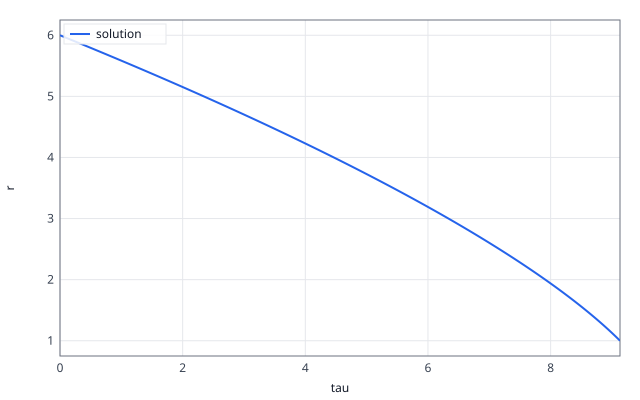

In [5]:
clear
r_s = 1;
odeplot([-sqrt(r_s/r), 1/(1-r_s/r)], [r t], tau, [6 0], 0, 9.7, [tau r])

But the distant observer's time $t$ runs away to infinity as $r \to r_s$: from outside, the infalling object freezes at
the horizon, ever more redshifted, and is never seen to cross:

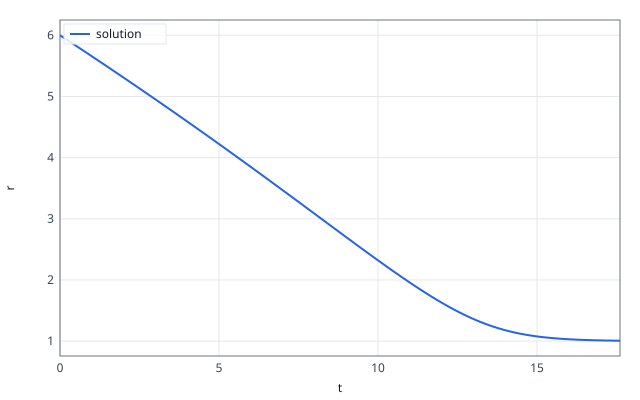

In [6]:
odeplot([-sqrt(r_s/r), 1/(1-r_s/r)], [r t], tau, [6 0], 0, 9.125, [t r])

## 5. Flamm's paraboloid

The space around the black hole at one moment, in the equatorial plane, has metric $dr^2/(1 - r_s/r) + r^2 d\phi^2$. It
is the surface $z = 2\sqrt{r_s(r - r_s)}$ in flat space, the "gravity well" of popular pictures. Galileo checks that:

In [7]:
clear
inducedmetric([r*cos(phi) r*sin(phi) 2*sqrt(r_s*(r-r_s))], [r phi])

$$ds^2 = \frac{r}{r - r_{s}}\, dr^2 + r^{2}\, d\phi^2$$

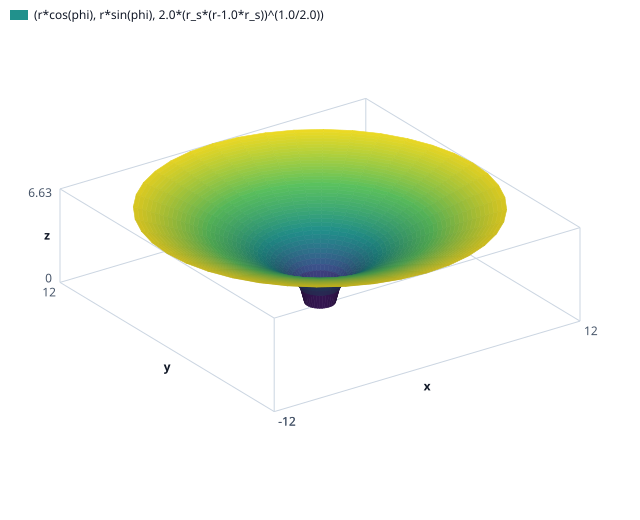

In [8]:
r_s = 1;
surface(r*cos(phi), r*sin(phi), 2*sqrt(r_s*(r-r_s)), r, 1, 12, phi, 0, 2*pi)

Radial distances near the horizon are stretched: the throat at $r = r_s$ is the horizon. Part 5 draws orbits on this
surface.

## 6. Spinning black holes: Kerr

Real black holes spin. Roy Kerr found the solution in 1963. In Boyer–Lindquist coordinates, with spin parameter $a$
(angular momentum per unit mass) and $\Sigma = r^2 + a^2\cos^2\theta$, $\Delta = r^2 - r_s r + a^2$:

In [9]:
clear
kerr = metric([t r theta phi], [-(1-r_s*r/(r^2+a^2*cos(theta)^2)), 0, 0, -r_s*r*a*sin(theta)^2/(r^2+a^2*cos(theta)^2); 0, (r^2+a^2*cos(theta)^2)/(r^2-r_s*r+a^2), 0, 0; 0, 0, r^2+a^2*cos(theta)^2, 0; -r_s*r*a*sin(theta)^2/(r^2+a^2*cos(theta)^2), 0, 0, (r^2+a^2+r_s*r*a^2*sin(theta)^2/(r^2+a^2*cos(theta)^2))*sin(theta)^2])

$$ds^2 = - - \frac{r r_{s}}{a^{2} \cos^{2}\left(\theta\right) + r^{2}} + 1\, dt^2 - \frac{2 a r r_{s} \sin^{2}\left(\theta\right)}{a^{2} \cos^{2}\left(\theta\right) + r^{2}}\, dt\, d\phi + \frac{a^{2} \cos^{2}\left(\theta\right) + r^{2}}{a^{2} + r^{2} - r r_{s}}\, dr^2 + \left(a^{2} \cos^{2}\left(\theta\right) + r^{2}\right)\, d\theta^2 + \left(a^{2} + \frac{a^{2} r r_{s} \sin^{2}\left(\theta\right)}{a^{2} \cos^{2}\left(\theta\right) + r^{2}} + r^{2}\right) \sin^{2}\left(\theta\right)\, d\phi^2$$

The off-diagonal $dt\,d\phi$ term means spacetime itself is dragged around the hole (*frame dragging*). Checking that
Kerr is a vacuum solution is a serious computation, about a minute:

In [10]:
riccitensor(kerr)

**Ricci tensor** (coordinates $t$, $r$, $\theta$, $\phi$)

$$\begin{aligned}
R = 0 \quad\text{(all components)}
\end{aligned}$$

The horizon is where $\Delta = 0$, at $r_+ = r_s/2 + \sqrt{r_s^2/4 - a^2}$. Outside it lies the **ergosphere**, where
$g_{tt} > 0$, which extends to $r_E = r_s/2 + \sqrt{r_s^2/4 - a^2\cos^2\theta}$. Inside the ergosphere nothing can stand
still; everything is dragged around with the hole. Here are both for $r_s = 1$, $a = 0.45$ (the outer surface is cut open
so you can see the horizon inside):

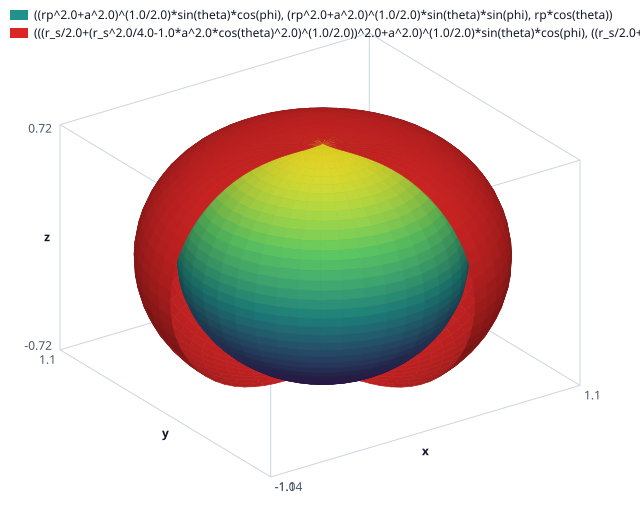

In [11]:
r_s = 1;
a = 0.45;
rp = eval(r_s/2 + sqrt(r_s^2/4 - a^2));
horizon = surface(sqrt(rp^2+a^2)*sin(theta)*cos(phi), sqrt(rp^2+a^2)*sin(theta)*sin(phi), rp*cos(theta), theta, 0, pi, phi, 0, 2*pi);
ergo = surface(sqrt((r_s/2+sqrt(r_s^2/4-a^2*cos(theta)^2))^2+a^2)*sin(theta)*cos(phi), sqrt((r_s/2+sqrt(r_s^2/4-a^2*cos(theta)^2))^2+a^2)*sin(theta)*sin(phi), (r_s/2+sqrt(r_s^2/4-a^2*cos(theta)^2))*cos(theta), theta, 0, pi, phi, 5.04, 9.44);
show(horizon, ergo)

The ergosphere touches the horizon at the poles and bulges out at the equator. Roger Penrose showed that energy can
be extracted from a spinning black hole through the ergosphere, which may power the jets of quasars.

## Summary

* The Schwarzschild horizon $r = r_s$ is a coordinate effect; $r = 0$ is a true singularity (Kretschmann).
* Tides at the horizon scale like $1/M^2$: deadly for small black holes, gentle for supermassive ones.
* Infall takes finite proper time but infinite coordinate time.
* Kerr black holes have frame dragging and an ergosphere.

Next: [Orbits](05-orbits.ipynb): planets around the Sun and the precession of Mercury.